# Florida ZHVI: Time-Aware Modeling

The goal is to predict Florida's next monthly Zillow Home Value Index from information available before that month. This revision fixes two important issues in the earlier model: it keeps all valid Florida history and uses time-series cross-validation rather than shuffled or ordinary cross-validation.

## Modeling plan

- Hold out the latest 20% of months as a final test period.
- Use expanding-window cross-validation inside the training period.
- Compare a persistence baseline with linear regression, tuned ridge regression, tuned random forest, and tuned gradient boosting.
- Choose the final model using cross-validation MAE, then evaluate it once on the holdout period.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({"figure.figsize": (11, 6), "figure.dpi": 110})
dollar_thousands = FuncFormatter(lambda x, _: f"${x/1000:,.0f}K")

DATA_PATH = Path("../data/zhvi.csv")
FIGURE_DIR = Path("../figures")
RESULTS_DIR = Path("../results")
MODEL_DIR = Path("../models")
for folder in (FIGURE_DIR, RESULTS_DIR, MODEL_DIR):
    folder.mkdir(exist_ok=True)

## Load the target series

In [2]:
raw = pd.read_csv(DATA_PATH)
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"])
florida = raw.set_index("Date")["Florida"].dropna().sort_index().rename("target")

print(f"Florida observations: {len(florida):,}")
print(f"Date range: {florida.index.min():%B %Y} to {florida.index.max():%B %Y}")
print(f"Missing values after selection: {florida.isna().sum()}")

Florida observations: 313
Date range: January 2000 to January 2026
Missing values after selection: 0


## Features use past values only

In [3]:
frame = florida.to_frame()
for lag in (1, 2, 3, 6, 12):
    frame[f"lag_{lag}"] = florida.shift(lag)

frame["rolling_mean_3"] = florida.shift(1).rolling(3).mean()
frame["rolling_mean_6"] = florida.shift(1).rolling(6).mean()
frame["rolling_std_6"] = florida.shift(1).rolling(6).std()
frame["month_sin"] = np.sin(2 * np.pi * frame.index.month / 12)
frame["month_cos"] = np.cos(2 * np.pi * frame.index.month / 12)
frame = frame.dropna()

X = frame.drop(columns="target")
y = frame["target"]
print(f"Modeling rows after creating lags: {len(frame):,}")
X.head()

Modeling rows after creating lags: 301


,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_std_6,month_sin,month_cos
Date,,,,,,,,,,
2001-01-01,113215.573288,112487.410818,111781.426609,109794.480951,106839.437513,112494.803572,111469.581259,1279.837128,0.500000,8.660254e-01
2001-02-01,113881.384598,113215.573288,112487.410818,110436.545638,107070.861680,113194.789568,112150.731867,1297.455415,0.866025,5.000000e-01
2001-03-01,114542.868845,113881.384598,113215.573288,111102.050253,107351.393901,113879.942244,112835.119068,1295.416738,1.000000,6.123234e-17
2001-04-01,115234.362310,114542.868845,113881.384598,111781.426609,107921.643751,114552.871918,113523.837745,1288.205165,0.866025,-5.000000e-01
2001-05-01,116051.183339,115234.362310,114542.868845,112487.410818,108536.596763,115276.138165,114235.463866,1312.278287,0.500000,-8.660254e-01


## Chronological train and test split

Training: Jan 2001 to Dec 2020 (240 months)
Holdout:  Jan 2021 to Jan 2026 (61 months)


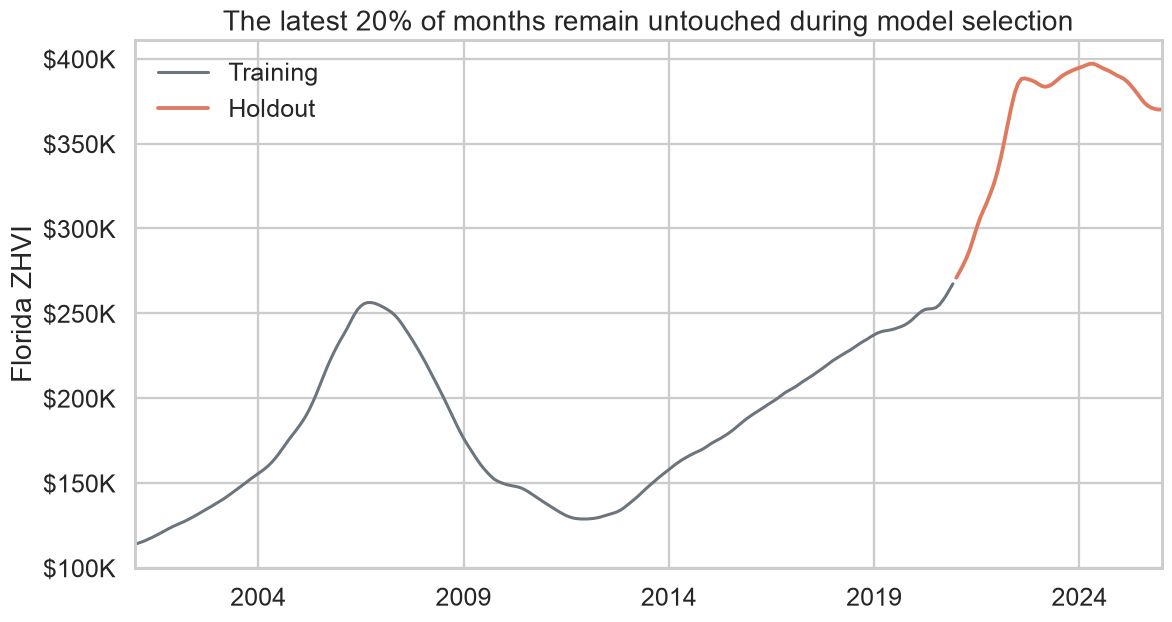

In [4]:
split_index = int(len(frame) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Training: {y_train.index.min():%b %Y} to {y_train.index.max():%b %Y} ({len(y_train)} months)")
print(f"Holdout:  {y_test.index.min():%b %Y} to {y_test.index.max():%b %Y} ({len(y_test)} months)")

ax = y_train.plot(label="Training", color="#6C757D", linewidth=2)
y_test.plot(ax=ax, label="Holdout", color="#E07A5F", linewidth=2.5)
ax.set_title("The latest 20% of months remain untouched during model selection")
ax.set_xlabel("")
ax.set_ylabel("Florida ZHVI")
ax.yaxis.set_major_formatter(dollar_thousands)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_train_test_split.png", bbox_inches="tight")
plt.show()

## Expanding-window validation

`TimeSeriesSplit` preserves chronological order. Each validation fold occurs after its training fold, so the model never trains on observations from the future.

In [5]:
tscv = TimeSeriesSplit(n_splits=5)

In [6]:
def score_holdout(name, prediction, cv_mae, parameters=""):
    return {
        "model": name,
        "best_parameters": parameters,
        "cv_mae": float(cv_mae),
        "test_mae": mean_absolute_error(y_test, prediction),
        "test_rmse": mean_squared_error(y_test, prediction) ** 0.5,
        "test_r2": r2_score(y_test, prediction),
        "test_mape_pct": np.mean(np.abs((y_test - prediction) / y_test)) * 100,
    }


predictions = {"actual": y_test, "persistence": X_test["lag_1"]}
baseline_fold_mae = []
for _, validation_index in tscv.split(X_train):
    baseline_fold_mae.append(
        mean_absolute_error(y_train.iloc[validation_index], X_train.iloc[validation_index]["lag_1"])
    )

records = [
    score_holdout(
        "Persistence baseline",
        predictions["persistence"],
        np.mean(baseline_fold_mae),
        "Prediction equals prior month's value",
    )
]

## Model 1: linear regression

In [7]:
linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])
linear_cv_mae = -cross_val_score(
    linear, X_train, y_train, scoring="neg_mean_absolute_error", cv=tscv
).mean()
linear.fit(X_train, y_train)
predictions["linear"] = linear.predict(X_test)
records.append(score_holdout("Linear regression", predictions["linear"], linear_cv_mae))

## Model 2: ridge regression with time-aware tuning

In [8]:
ridge_search = GridSearchCV(
    Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge()),
    ]),
    {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_mean_absolute_error",
    cv=tscv,
)
ridge_search.fit(X_train, y_train)
predictions["ridge"] = ridge_search.predict(X_test)
records.append(score_holdout(
    "Ridge regression",
    predictions["ridge"],
    -ridge_search.best_score_,
    str(ridge_search.best_params_),
))
ridge_search.best_params_

{'model__alpha': 0.01}

## Model 3: random forest with time-aware tuning

In [9]:
forest_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, None],
        "min_samples_leaf": [1, 3, 6],
    },
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
)
forest_search.fit(X_train, y_train)
predictions["random_forest"] = forest_search.predict(X_test)
records.append(score_holdout(
    "Random forest",
    predictions["random_forest"],
    -forest_search.best_score_,
    str(forest_search.best_params_),
))
forest_search.best_params_

{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}

## Model 4: gradient boosting with time-aware tuning

In [10]:
boost_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [1, 2, 3],
    },
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
)
boost_search.fit(X_train, y_train)
predictions["gradient_boosting"] = boost_search.predict(X_test)
records.append(score_holdout(
    "Gradient boosting",
    predictions["gradient_boosting"],
    -boost_search.best_score_,
    str(boost_search.best_params_),
))
boost_search.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

## Model comparison

In [11]:
metrics = pd.DataFrame(records).sort_values("cv_mae").reset_index(drop=True)
metrics["final_model"] = metrics["model"].eq("Ridge regression")
metrics.to_csv("../model_metrics.csv", index=False)

metrics_display = metrics.copy()
for column in ["cv_mae", "test_mae", "test_rmse"]:
    metrics_display[column] = metrics_display[column].map(lambda x: f"${x:,.0f}")
metrics_display["test_r2"] = metrics_display["test_r2"].map(lambda x: f"{x:.3f}")
metrics_display["test_mape_pct"] = metrics_display["test_mape_pct"].map(lambda x: f"{x:.2f}%")
metrics_display

,model,best_parameters,cv_mae,test_mae,test_rmse,test_r2,test_mape_pct,final_model
0,Ridge regression,{'model__alpha': 0.01},"$1,292",$886,"$1,268",0.999,0.25%,True
1,Persistence baseline,Prediction equals prior month's value,"$1,812","$2,733","$3,813",0.989,0.80%,False
2,Linear regression,,"$2,680",$376,$486,1.000,0.10%,False
3,Gradient boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...","$17,433","$102,536","$109,044",-7.692,27.13%,False
4,Random forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...","$17,944","$101,385","$107,966",-7.521,26.81%,False


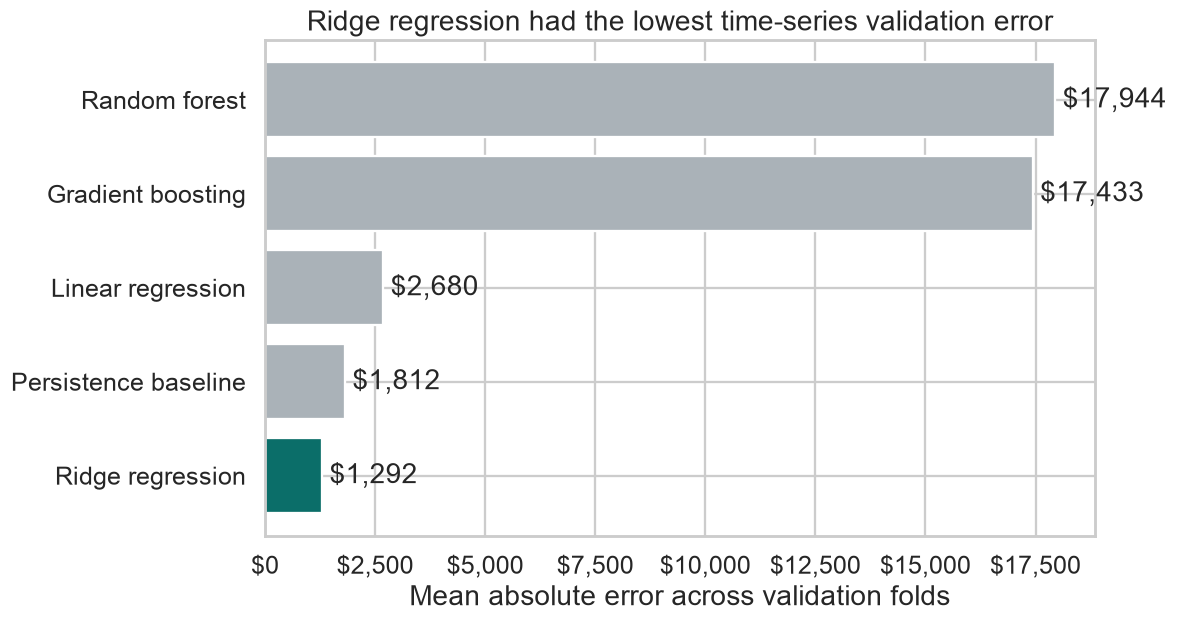

In [12]:
comparison = metrics.sort_values("cv_mae", ascending=True)
fig, ax = plt.subplots(figsize=(11, 6))
colors = ["#0B6E69" if name == "Ridge regression" else "#AAB2B8" for name in comparison["model"]]
bars = ax.barh(comparison["model"], comparison["cv_mae"], color=colors)
ax.set_title("Ridge regression had the lowest time-series validation error")
ax.set_xlabel("Mean absolute error across validation folds")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in comparison["cv_mae"]], padding=5)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_model_cv_comparison.png", bbox_inches="tight")
plt.show()

Ridge regression is the final model because it had the lowest cross-validation MAE. The holdout set remains independent of that choice. Linear regression happened to score better on the holdout, but selecting it after seeing the holdout would turn the test period into another tuning set.

## Final holdout results

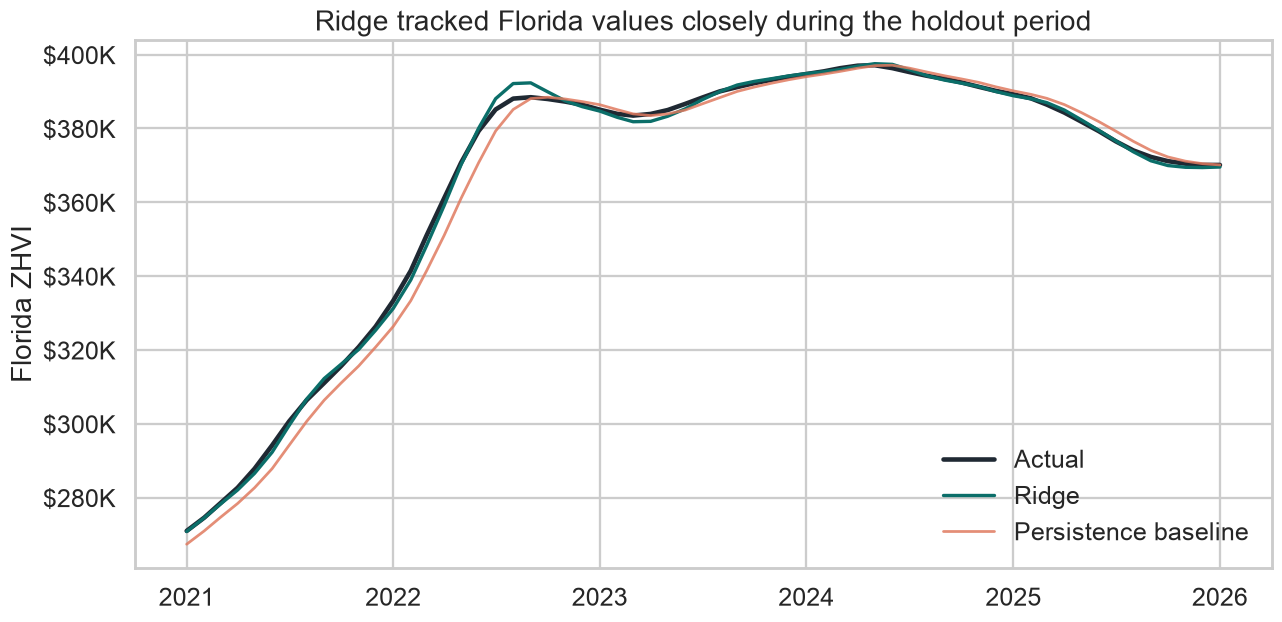

Ridge holdout MAE: $886
Ridge holdout MAPE: 0.25%
MAE improvement over persistence: 67.6%


In [13]:
prediction_frame = pd.DataFrame(predictions)
prediction_frame.to_csv(RESULTS_DIR / "holdout_predictions.csv")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(prediction_frame.index, prediction_frame["actual"], label="Actual", color="#1F2933", linewidth=3)
ax.plot(prediction_frame.index, prediction_frame["ridge"], label="Ridge", color="#0B6E69", linewidth=2.2)
ax.plot(prediction_frame.index, prediction_frame["persistence"], label="Persistence baseline", color="#E07A5F", linewidth=1.8, alpha=0.85)
ax.set_title("Ridge tracked Florida values closely during the holdout period")
ax.set_xlabel("")
ax.set_ylabel("Florida ZHVI")
ax.yaxis.set_major_formatter(dollar_thousands)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_holdout_predictions.png", bbox_inches="tight")
plt.show()

ridge_metrics = metrics.loc[metrics["model"] == "Ridge regression"].iloc[0]
baseline_metrics = metrics.loc[metrics["model"] == "Persistence baseline"].iloc[0]
improvement = (1 - ridge_metrics["test_mae"] / baseline_metrics["test_mae"]) * 100
print(f"Ridge holdout MAE: ${ridge_metrics['test_mae']:,.0f}")
print(f"Ridge holdout MAPE: {ridge_metrics['test_mape_pct']:.2f}%")
print(f"MAE improvement over persistence: {improvement:.1f}%")

## Residual review

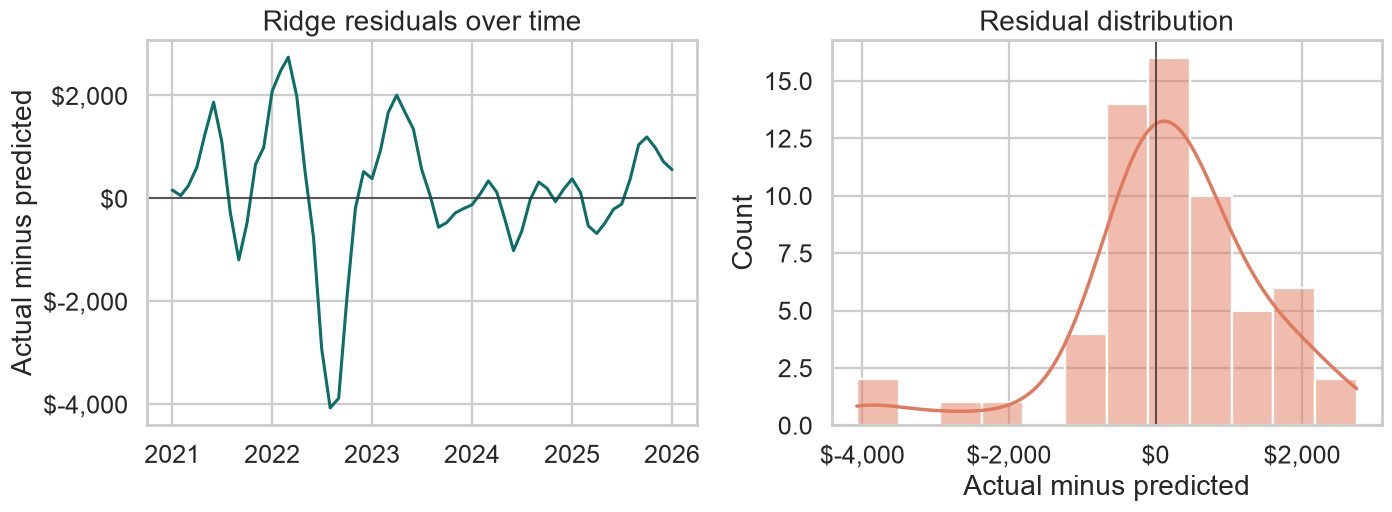

Mean residual: $178
Largest absolute residual: $4,075


In [14]:
ridge_residuals = y_test - prediction_frame["ridge"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(ridge_residuals.index, ridge_residuals, color="#0B6E69", linewidth=2)
axes[0].axhline(0, color="#333333", linewidth=1)
axes[0].set_title("Ridge residuals over time")
axes[0].set_xlabel("")
axes[0].set_ylabel("Actual minus predicted")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

sns.histplot(ridge_residuals, bins=12, kde=True, ax=axes[1], color="#E07A5F")
axes[1].axvline(0, color="#333333", linewidth=1)
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Actual minus predicted")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_ridge_residuals.png", bbox_inches="tight")
plt.show()

print(f"Mean residual: ${ridge_residuals.mean():,.0f}")
print(f"Largest absolute residual: ${ridge_residuals.abs().max():,.0f}")

In [15]:
joblib.dump(
    {
        "model": ridge_search.best_estimator_,
        "feature_names": list(X.columns),
        "training_end": str(y_train.index.max().date()),
        "target": "Florida monthly ZHVI",
    },
    MODEL_DIR / "final_ridge_model.joblib",
)

['../models/final_ridge_model.joblib']

## Conclusions

1. Ridge regression produced the best expanding-window validation MAE and beat the persistence baseline on the independent holdout period.
2. Tree ensembles struggled because the holdout values rose above most of the training range. Standard random forests and gradient boosting trees interpolate well but do not naturally extrapolate a rising level series.
3. A one-month ZHVI forecast can support monitoring and budgeting, but it cannot identify an undervalued market by itself.

## Limitations and next steps

- ZHVI is a state-level index, not a transaction-level property price.
- The model uses only the target's history. Mortgage rates, inventory, rents, income, and migration could improve both explanation and longer-horizon forecasting.
- The dataset source noted in the original notebook was Kaggle, but the exact Kaggle page was not recorded. The underlying measure is Zillow ZHVI.
- A future version should test multiple forecast horizons and use metro- or county-level data for investment decisions.